# 파이썬 실습: 주문 파일로 합계 내기

**이 노트북에서 할 일**

1. 주문 파일 두 개와 가격표를 만들고, 앞 절의 클래스와 함수를 부품으로 준비합니다.
2. 부품을 한 함수로 조립해 orders.txt의 합계를 내고, 결과를 기록장에 적습니다(실행 1).
3. 파일 이름 하나만 bad_orders.txt로 바꿔 다시 실행하고, 두 기록장을 비교합니다(실행 2).

**준비물** — API 키 불필요. 주문 파일은 노트북이 임시 폴더에 직접 만듭니다.
언어 모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

1~12절과 같은 실습 폴더 `labs/part1/ch02-python`의 `.venv`를 커널로 고르고, 첫 셀부터 순서대로 실행합니다.
기본 경로(A)와 확장 경로(B)가 함께 배운 1~7절 문법과 검사 줄 `assert`만 씁니다. 새 문법은 없습니다.

## 오늘 볼 그림

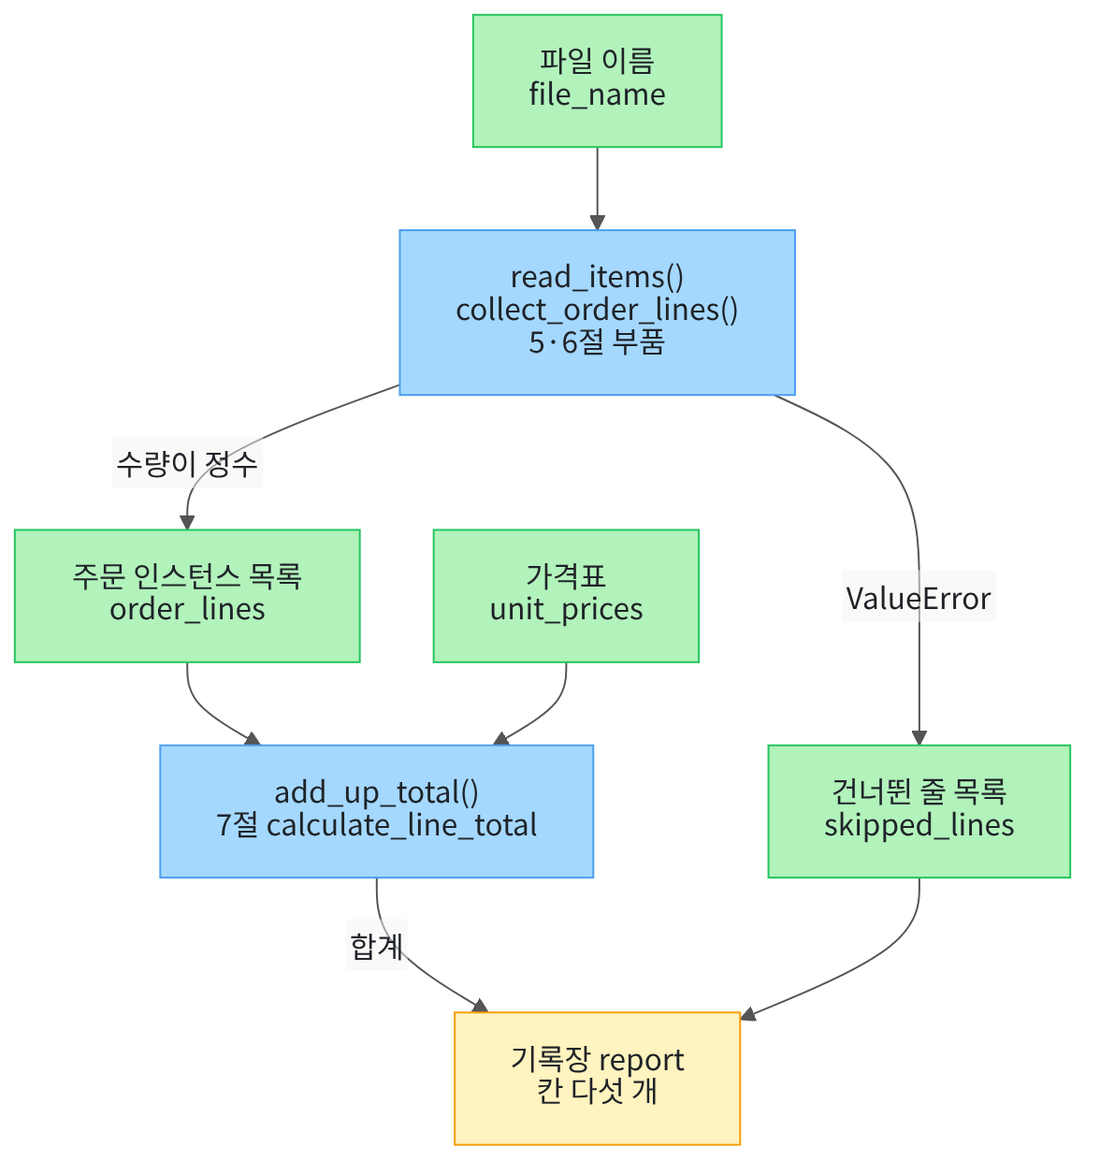

위에서 아래로 읽습니다. 파란 상자는 이 노트북에서 조립하는 함수이고, 초록 상자는 함수에 들어가고 나오는 값입니다. 노란 상자는 결과를 적는 기록장입니다.

파일에서 읽은 줄은 주문 인스턴스 목록과 건너뛴 줄 목록 가운데 한 곳으로 갑니다. 두 갈래는 모두 맨 아래 기록장에 모입니다.

## 1. 준비

이 노트북은 주문 파일 두 개를 만듭니다. 5·7·8·12절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
따로 설치할 패키지는 없습니다. 준비 셀은 Python에 들어 있는 모듈 os와 tempfile만 불러옵니다.

In [1]:
# 주문 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch02-13-")
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. 실습 주제 — 주문 파일로 합계 내기

작은 문구점이 주문을 파일로 받습니다. 한 줄에 상품 이름과 수량을 쉼표로 이어 적습니다. 5절에서 만든 orders.txt와 같은 모양입니다.
파일을 읽어 주문마다 금액을 계산하고 합계를 냅니다.

그런데 수량 자리에 숫자가 아닌 글자가 들어간 줄도 있습니다. 5절 bad_orders.txt의 「연필,많이」입니다.
이번에는 그 줄을 합계에서 빼되, 버리지 않고 기록장에 남깁니다. 정상 줄 「노트,2」는 그대로 합계에 넣습니다.

새 문법은 없습니다. 1~7절에서 따로 배운 부품을 한 함수로 조립하고, 파일 이름 하나만 바꿔 두 번 실행합니다.

## 3. 재료 만들기 — 주문 파일 두 개와 가격표

5절과 같은 글로 파일 두 개를 저장합니다. orders.txt에는 연필 3개와 노트 2개가 있습니다.
파일 bad_orders.txt는 첫 줄의 수량 자리에만 글자 「많이」가 들어 있습니다.

저장한 뒤 모듈 os의 `listdir()`로 파일 이름 목록을 받습니다. 3절 `sorted()`로 순서를 정해 출력합니다.
실행 전에 예상합니다. 현재 작업 폴더에 파일 두 개가 보일 것입니다.

In [2]:
# 5절과 같은 주문 글 두 개를 파일 두 개에 저장합니다
order_text = """연필,3
노트,2
"""
# 수량 자리에 숫자가 아닌 글자 「많이」가 든 주문 글입니다
bad_order_text = """연필,많이
노트,2
"""
with open("orders.txt", "w", encoding="utf-8") as file:
    file.write(order_text)
with open("bad_orders.txt", "w", encoding="utf-8") as file:
    file.write(bad_order_text)
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['bad_orders.txt', 'orders.txt']


**결과 읽기** — 현재 작업 폴더의 파일은 `['bad_orders.txt', 'orders.txt']`로 예상과 같습니다.
실행 1은 orders.txt를, 실행 2는 bad_orders.txt를 읽습니다.

상품마다 단가를 적은 가격표를 3절의 딕셔너리로 만듭니다. 키는 상품 이름이고, 값은 단가(원)입니다.
단가는 연필 1000원, 노트 2500원입니다. 챕터 소개의 기본 경로(A트랙) 보충 과제 6과 같은 값입니다.

실행 전에 예상합니다. 키 「연필」로 읽은 단가는 1000일 것입니다.

In [3]:
# 상품 이름을 키로, 단가(원)를 값으로 담은 가격표를 만듭니다
unit_prices = {"연필": 1000, "노트": 2500}
# 3절처럼 대괄호에 키를 넣어 값을 읽습니다
pencil_price = unit_prices["연필"]
print("가격표:", unit_prices)
print("연필 단가:", pencil_price)

가격표: {'연필': 1000, '노트': 2500}
연필 단가: 1000


**결과 읽기** — 가격표는 `{'연필': 1000, '노트': 2500}`이고, 연필 단가는 `1000`으로 예상과 같습니다.

## 4. 부품 준비 — 앞 절의 클래스와 함수

첫 부품은 6절의 클래스 `OrderLine`입니다. 상품 이름과 수량을 인스턴스 하나에 함께 저장합니다.
6절에는 수량을 더하는 메서드 `add_count()`도 있었습니다. 이번 실습에서는 쓰지 않아서 초기화 메서드만 적습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [4]:
# 6절 클래스: 상품 이름과 수량을 인스턴스에 함께 저장합니다
class OrderLine:
    # 인스턴스를 만들 때 저절로 실행되어 두 값을 저장합니다
    def __init__(self, name, count):
        self.name = name
        self.count = count

**결과 읽기** — 예상대로 출력이 없습니다. 정의 셀은 클래스 이름과 초기화 메서드를 기억해 둡니다.

둘째 부품은 7절의 함수 `calculate_line_total()`입니다. 단가와 수량을 곱해 주문 줄 금액을 반환합니다.
7절에서 적은 타입힌트까지 그대로 가져옵니다. 7절에서 본 것처럼, 타입힌트는 표시일 뿐이라 값을 검사하지 않습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [5]:
# 7절 함수: 단가와 수량을 받아 주문 줄 금액을 반환합니다
def calculate_line_total(unit_price: int, quantity: int = 1) -> int:
    line_total = unit_price * quantity
    return line_total

**결과 읽기** — 예상대로 출력이 없습니다. 함수를 정의만 하고 아직 부르지 않았습니다.

두 부품을 연필 3개로 먼저 확인합니다. 인스턴스를 만들고, 속성 name을 키로 가격표에서 단가를 읽습니다.
그 단가와 속성 count를 함수에 넣습니다.

실행 전에 예상합니다. 연필 1000원짜리 3개이므로 금액은 3000일 것입니다.

In [6]:
# 두 부품을 연필 3개로 확인합니다
pencil = OrderLine("연필", 3)
# 인스턴스의 속성 name을 키로 써서 가격표에서 단가를 읽습니다
pencil_price = unit_prices[pencil.name]
pencil_total = calculate_line_total(pencil_price, pencil.count)
print("상품 이름:", pencil.name)
print("수량:", pencil.count)
print("연필 금액:", pencil_total)

상품 이름: 연필
수량: 3
연필 금액: 3000


**결과 읽기** — 상품 이름은 `연필`, 수량은 `3`, 연필 금액은 `3000`으로 예상과 같습니다.
인스턴스의 속성과 가격표 딕셔너리, 금액 함수가 함께 동작했습니다.

셋째 부품은 5절의 함수 `read_items()`입니다. 파일을 읽어 줄 목록을 반환합니다. 5절 정의를 그대로 가져옵니다.

5절 함수에는 타입힌트가 없었습니다. 이번 실습에서 새로 정의하는 함수도 5절 모양대로 타입힌트 없이 씁니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [7]:
# 5절 함수: 파일 이름을 받아 파일의 줄 목록을 반환합니다
def read_items(file_name):
    with open(file_name, "r", encoding="utf-8") as file:
        text = file.read()
    # splitlines()는 줄바꿈 자리에서 글을 나눠 문자열 목록을 반환합니다
    lines = text.splitlines()
    return lines

**결과 읽기** — 예상대로 출력이 없습니다. 본문의 `with` 블록은 함수를 부를 때 실행됩니다.

넷째 부품은 5절 `parse_order()`를 조금 고친 함수 `make_order_line()`입니다. 5절 함수는 줄 하나를 (상품 이름, 수량) 튜플로 바꿨습니다.
이 함수는 튜플 대신 6절의 `OrderLine` 인스턴스를 만들어 반환합니다.

수량 글자를 `int()`로 바꾸는 줄은 5절과 같습니다. 그래서 「많이」 같은 글자가 오면 이 줄에서 `ValueError`가 납니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [8]:
# 주문 한 줄을 받아 OrderLine 인스턴스로 바꿔 반환합니다(5절 parse_order를 고친 판)
def make_order_line(line):
    name, count_text = line.split(",")
    # 수량 글자가 숫자가 아니면 이 줄에서 ValueError가 납니다
    count = int(count_text)
    order_line = OrderLine(name, count)
    return order_line

**결과 읽기** — 예상대로 출력이 없습니다. 이제 부품 네 개를 모두 정의했습니다.

두 함수를 orders.txt로 확인합니다. 줄 목록을 읽고, 첫 줄을 인스턴스로 바꿔 속성과 자료형을 봅니다.

실행 전에 예상합니다. 줄 목록은 5절과 같은 두 줄이고, 첫 줄은 연필 3개일 것입니다.

In [9]:
# 파일을 줄 목록으로 읽고, 첫 줄을 OrderLine 인스턴스로 바꿔 봅니다
lines = read_items("orders.txt")
first_line = make_order_line(lines[0])
first_type = type(first_line)
print("줄 목록:", lines)
print("첫 줄의 상품 이름과 수량:", first_line.name, first_line.count)
print("첫 줄의 자료형:", first_type)

줄 목록: ['연필,3', '노트,2']
첫 줄의 상품 이름과 수량: 연필 3
첫 줄의 자료형: <class '__main__.OrderLine'>


**결과 읽기** — 줄 목록은 `['연필,3', '노트,2']`이고, 첫 줄의 상품 이름과 수량은 `연필 3`입니다. 자료형은 `<class '__main__.OrderLine'>`입니다.
파일의 글자 3이 정수 3으로 바뀌어 인스턴스의 속성 count에 들어갔습니다.

## 5. 부품 잇기 — 줄 목록에서 합계까지

부품을 두 함수로 잇습니다. 함수 `collect_order_lines()`는 줄 목록을 받아 줄마다 `make_order_line()`을 부릅니다.
인스턴스가 만들어진 줄은 주문 목록에 담습니다. 오류 `ValueError`가 난 줄은 건너뛴 줄 목록에 담고, 오류 메시지를 출력합니다.

5절 Before는 모든 오류를 빈 목록으로 바꿔 정상 줄 「노트,2」까지 사라졌습니다. 5절 After는 except 줄에 오류 이름을 적어 필요한 오류만 받았습니다.
이 함수도 오류 이름 `ValueError`만 받습니다. 받는 자리는 줄 하나를 바꾸는 곳이라, 나쁜 줄 하나만 건너뛰고 다음 줄은 계속 읽습니다.

5절 결론은 서로 다른 문제를 같은 빈 결과로 감추지 않는다는 것이었습니다. 이번 함수도 오류 메시지를 출력하고 건너뛴 줄 칸에 남겨, 받은 오류를 감추지 않습니다.

두 목록은 3절의 튜플 하나에 담아 반환합니다. 실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [10]:
# 줄 목록을 받아 줄마다 인스턴스를 만들고, 수량을 읽을 수 없는 줄은 따로 모아 두 목록을 반환합니다
def collect_order_lines(lines):
    order_lines = []
    skipped_lines = []
    for line in lines:
        try:
            order_line = make_order_line(line)
            order_lines.append(order_line)
        except ValueError as error:
            # 줄을 버리지 않고 건너뛴 줄 목록에 남기고, 오류 메시지도 보여 줍니다
            print("건너뛴 줄:", line, "/ 오류 메시지:", error)
            skipped_lines.append(line)
    return (order_lines, skipped_lines)

**결과 읽기** — 예상대로 출력이 없습니다. 파일을 읽는 일은 이 함수에 없고, 7번의 조립 함수가 맡습니다.

함수 `add_up_total()`은 인스턴스 목록과 가격표를 받아 합계를 반환합니다. 주문마다 가격표에서 단가를 읽고, 7절 함수로 금액을 계산합니다.
주문마다 금액을 출력하고, 3절의 `+=`로 합계에 더합니다.

가격표는 매개변수 `price_table`로 받습니다. 4절에서 배운 대로 함수 안에서 쓸 값은 인자로 넣습니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [11]:
# 인스턴스 목록과 가격표를 받아, 주문 줄 금액을 모두 더한 합계를 반환합니다
def add_up_total(order_lines, price_table):
    total = 0
    for order_line in order_lines:
        # 상품 이름 키로 가격표에서 단가를 읽습니다
        unit_price = price_table[order_line.name]
        line_total = calculate_line_total(unit_price, order_line.count)
        print(order_line.name, "금액:", line_total)
        total += line_total
    return total

**결과 읽기** — 예상대로 출력이 없습니다. 부품을 잇는 함수 두 개를 정의했습니다.

## 6. 기록장 보기 — 결과를 칸별로 출력하는 함수

두 실행의 결과를 비교하려면 결과를 같은 칸에 적어 둬야 합니다. 이 실습은 3절의 딕셔너리를 기록장으로 씁니다.
칸 이름(키)은 파일, 읽은 줄 수, 주문 수, 건너뛴 줄, 합계의 다섯 개입니다. 기록장은 다음 7번의 조립 함수가 채웁니다.

여기서는 기록장을 칸마다 한 줄씩 출력하는 함수를 만듭니다. 3절 `items()`로 키와 값의 짝을 차례로 읽습니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [12]:
# 기록장 딕셔너리의 칸을 한 줄에 하나씩 출력합니다
def print_report(report):
    # items()는 키와 값의 짝을 차례로 내놓습니다
    for key, value in report.items():
        print(key, "|", value)

**결과 읽기** — 예상대로 출력이 없습니다. 이 함수는 실행 1과 실행 2에서 한 번씩 부릅니다.

## 7. 조립하기 — 파일 이름 하나로 기록장까지

조립 함수 `summarize_orders()`는 파일 이름과 가격표를 받습니다. 파일 읽기, 줄 나누기, 합계, 기록장 채우기를 차례로 합니다.
줄마다 붙인 주석에 그 줄이 쓰는 절을 적었습니다.

반환값 두 개를 받는 줄은 3절의 풀어 담기입니다. 기록장은 빈 딕셔너리를 만든 뒤 3절처럼 키를 하나씩 추가합니다.
칸 「읽은 줄 수」는 파일에서 읽은 줄 목록의 길이입니다. 실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [13]:
# 조립: 파일 이름과 가격표를 받아 읽기 → 합계 → 기록장까지 이어 붙입니다
def summarize_orders(file_name, price_table):
    # 5절 파일 읽기
    lines = read_items(file_name)
    # 5절 try/except, 6절 OrderLine
    order_lines, skipped_lines = collect_order_lines(lines)
    # 3절 가격표 딕셔너리, 7절 calculate_line_total
    total = add_up_total(order_lines, price_table)
    # 3절 딕셔너리 기록장에 칸을 하나씩 적습니다
    report = {}
    report["파일"] = file_name
    report["읽은 줄 수"] = len(lines)
    report["주문 수"] = len(order_lines)
    report["건너뛴 줄"] = skipped_lines
    report["합계"] = total
    return report

**결과 읽기** — 예상대로 출력이 없습니다. 조립이 끝났습니다. 이제 파일 이름만 넣어 부르면 됩니다.

## 8. 실행 1 — orders.txt의 합계 내기

변수 `file_name`에 `"orders.txt"`를 담아 조립 함수를 부릅니다. 반환된 기록장은 `report_1`에 담고 칸별로 출력합니다.

실행 전에 예상합니다. 두 줄 모두 수량이 숫자라서 건너뛴 줄은 없을 것입니다.
금액은 연필 3000원과 노트 2500 × 2 = 5000원이고, 합계는 8000원일 것입니다.

In [14]:
# 실행 1: 주문 파일 orders.txt로 조립한 함수를 부르고 기록장을 봅니다
file_name = "orders.txt"
report_1 = summarize_orders(file_name, unit_prices)
print("기록장:")
print_report(report_1)

연필 금액: 3000
노트 금액: 5000
기록장:
파일 | orders.txt
읽은 줄 수 | 2
주문 수 | 2
건너뛴 줄 | []
합계 | 8000


**결과 읽기** — 먼저 `연필 금액: 3000`과 `노트 금액: 5000`이 나왔습니다. 기록장은 `읽은 줄 수 | 2`, `주문 수 | 2`, `건너뛴 줄 | []`, `합계 | 8000`입니다.
예상과 같습니다. 「건너뛴 줄」 출력이 없으므로 except 블록은 한 번도 실행되지 않았습니다.

읽은 두 줄이 모두 주문이 되었고, 합계는 연필과 노트 금액을 더한 값입니다.

## 9. 실행 2 — 파일 이름 하나만 바꾸기

바꾸는 값은 `file_name` 하나입니다. 값을 `"bad_orders.txt"`로 바꾸고, 같은 조립 함수와 같은 가격표로 다시 부릅니다. 기록장은 `report_2`에 담습니다.

실행 전에 예상합니다. 첫 줄 「연필,많이」는 5절처럼 `int()` 줄에서 `ValueError`가 날 것입니다.
이번에는 셀이 멈추지 않고 그 줄만 건너뛸 것입니다. 노트 금액 5000원만 합계에 들어가고, 읽은 줄 수는 2 그대로일 것입니다.

In [15]:
# 실행 2: 파일 이름 하나만 bad_orders.txt로 바꿔 같은 함수를 부릅니다
file_name = "bad_orders.txt"
report_2 = summarize_orders(file_name, unit_prices)
print("기록장:")
print_report(report_2)

건너뛴 줄: 연필,많이 / 오류 메시지: invalid literal for int() with base 10: '많이'
노트 금액: 5000
기록장:
파일 | bad_orders.txt
읽은 줄 수 | 2
주문 수 | 1
건너뛴 줄 | ['연필,많이']
합계 | 5000


**결과 읽기** — 첫 줄은 `건너뛴 줄: 연필,많이 / 오류 메시지: invalid literal for int() with base 10: '많이'`입니다. 다음 줄은 `노트 금액: 5000`입니다.
기록장은 `읽은 줄 수 | 2`, `주문 수 | 1`, `건너뛴 줄 | ['연필,많이']`, `합계 | 5000`으로 예상과 같습니다.

오류 메시지는 5절에서 본 것과 같습니다. 5절 After에서는 이 오류가 함수 밖으로 나왔습니다.
이번에는 줄 하나를 바꾸는 자리에서 받아, 나쁜 줄은 기록장에 남기고 정상 줄 「노트,2」는 합계에 넣었습니다.

## 10. 두 기록장 비교하기

두 기록장에서 같은 키의 값끼리 비교합니다. 기호 `!=`는 「두 값이 다른가」 비교입니다.
달라진 칸은 실행 1 값과 실행 2 값을 함께 출력하고, 같은 칸은 값 하나만 출력합니다. Ch 1 6절 점검표 비교와 같은 모양입니다.

셀 끝의 검사 줄 `assert`는 실행 2에서 읽은 줄이 하나도 사라지지 않았는지 확인합니다. 파일에서 읽은 줄 수가 주문 수와 건너뛴 줄 수를 더한 값과 같아야 합니다.
실행 전에 예상합니다. 읽은 줄 수만 같고, 나머지 네 칸은 달라질 것입니다.

In [16]:
# 두 기록장을 칸마다 비교하고, 달라진 칸의 수를 셉니다
changed_count = 0
for key, value_1 in report_1.items():
    value_2 = report_2[key]
    if value_1 != value_2:
        print("달라짐 |", key, "|", value_1, "->", value_2)
        changed_count += 1
    else:
        print("같음 |", key, "|", value_1)
print("달라진 칸 수:", changed_count)
# 실행 2에서 읽은 줄은 주문이나 건너뛴 줄 가운데 한 곳에 있어야 합니다
skipped_count = len(report_2["건너뛴 줄"])
assert report_2["읽은 줄 수"] == report_2["주문 수"] + skipped_count

달라짐 | 파일 | orders.txt -> bad_orders.txt
같음 | 읽은 줄 수 | 2
달라짐 | 주문 수 | 2 -> 1
달라짐 | 건너뛴 줄 | [] -> ['연필,많이']
달라짐 | 합계 | 8000 -> 5000
달라진 칸 수: 4


**결과 읽기** — 달라진 칸 수는 `4`입니다. `같음 | 읽은 줄 수 | 2` 한 칸만 같았습니다. 검사 줄 `assert`에서도 멈추지 않았습니다.
달라진 칸은 파일, `주문 수 | 2 -> 1`, `건너뛴 줄 | [] -> ['연필,많이']`, `합계 | 8000 -> 5000`입니다.

바꾼 값은 파일 이름 하나이고, 함수와 가격표는 그대로입니다. 그래서 파일 칸을 뺀 나머지 세 칸의 차이는 파일의 첫 줄 「연필,많이」에서 나왔습니다.
두 실행 모두 읽은 두 줄은 주문 목록이나 건너뛴 줄 목록 가운데 한 곳에 들어갔습니다.

## 정리

- 5절 파일 읽기와 예외, 6절 클래스, 3절 딕셔너리, 7절 금액 함수를 조립 함수 하나로 이었습니다.
- 실행 1(orders.txt)은 주문 2개, 건너뛴 줄 없음, 합계 8000원이었습니다.
- 실행 2에서 파일 이름만 바꾸자 「연필,많이」 한 줄이 기록장에 남았고, 합계는 5000원이었습니다.

이번에는 수량 글자가 잘못된 줄 하나만 실행했습니다. 가격표에 없는 상품 이름이나 쉼표가 없는 줄은 실행하지 않았습니다.
이 절로 Ch 2가 끝납니다. Ch 3에서는 파일의 바뀐 내용을 Git으로 기록합니다.